<h1 align="center" style="line-height: 200%; font-family: Vazirmatn; color: #0099cc;">
    Analysing Pharmaceutical Sales Data
</h1>

<div style="line-height: 200%; font-family: Vazirmatn; font-size: medium; text-align: justify;">

<p>
    This project analyses pharmaceutical sales data obtained from the Point-of-Sale (POS) system of an individual pharmacy.
    The original dataset contains approximately <strong>600,000 transactional records</strong> collected over a six-year period,
    from <strong>2014 to 2019</strong>.
</p>

<p>The dataset includes the following key information:</p>

<ul>
    <li>Date and time of each sale transaction</li>
    <li>Pharmaceutical drug brand name</li>
    <li>Quantity of each drug sold</li>
</ul>

<p>
    The analysis focuses on a selected group of <strong>57 pharmaceutical products</strong>. These drugs are classified according
    to the Anatomical Therapeutic Chemical (ATC) Classification System and belong to the following categories:
</p>

<ul>
    <li>
        <strong>M01AB:</strong> Anti-inflammatory and antirheumatic products, non-steroids;
        acetic acid derivatives and related substances
    </li>
    <li>
        <strong>M01AE:</strong> Anti-inflammatory and antirheumatic products, non-steroids;
        propionic acid derivatives
    </li>
    <li>
        <strong>N02BA:</strong> Other analgesics and antipyretics; salicylic acid and derivatives
    </li>
    <li>
        <strong>N02BE/B:</strong> Other analgesics and antipyretics; pyrazolones and anilides
    </li>
    <li>
        <strong>N05B:</strong> Psycholeptics; anxiolytic drugs
    </li>
    <li>
        <strong>N05C:</strong> Psycholeptics; hypnotics and sedatives
    </li>
    <li>
        <strong>R03:</strong> Drugs for obstructive airway diseases
    </li>
    <li>
        <strong>R06:</strong> Antihistamines for systemic use
    </li>
</ul>

<p>
    For time-series analysis, transaction-level sales records have been resampled into multiple time frequencies:
</p>

<ul>
    <li>Hourly sales data</li>
    <li>Daily sales data</li>
    <li>Weekly sales data</li>
    <li>Monthly sales data</li>
</ul>

<p>
    The dataset has already been preprocessed. The preprocessing stage included:
</p>

<ul>
    <li>Outlier detection and treatment</li>
    <li>Missing-value imputation</li>
    <li>Aggregation of transactional data across different time intervals</li>
</ul>

</div>


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pharma = pd.read_csv('salesdaily.csv')
pharma.head()
# pharma.info()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


<h3> 1.What are the total sales quantities for each drug category (ATC code)? 
</h3>

In [3]:
atc_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

total_sales_by_atc = pharma[atc_cols].sum().sort_values(ascending=False)
print(total_sales_by_atc)


N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


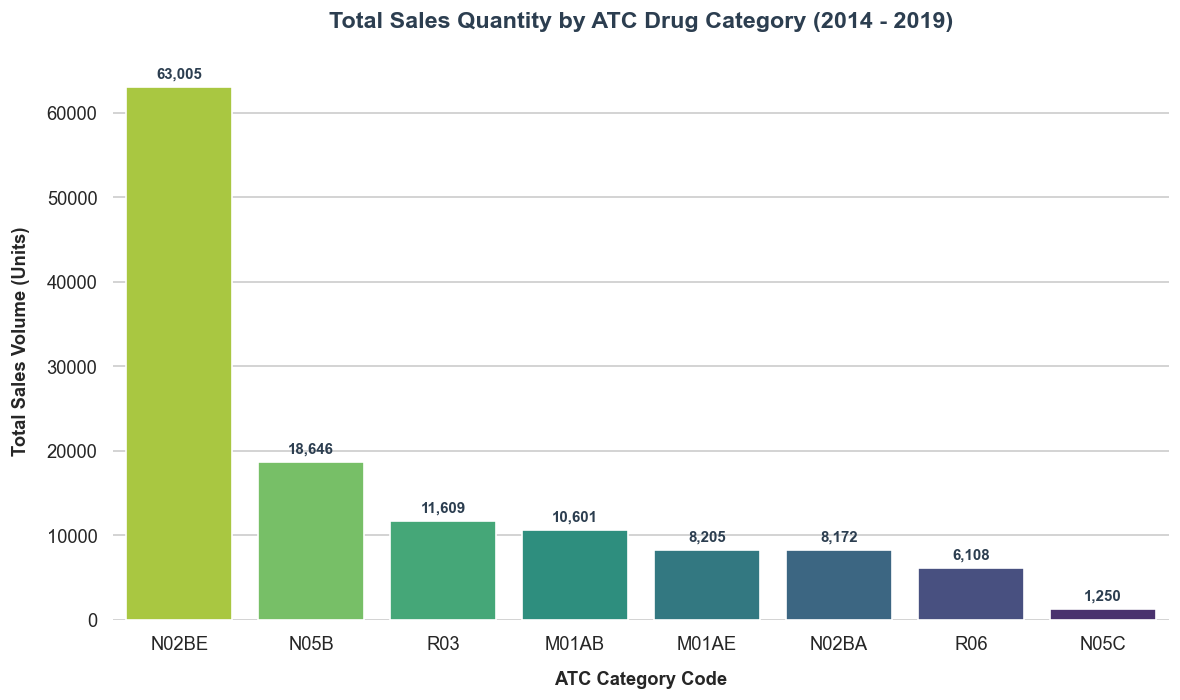

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

data = total_sales_by_atc.reset_index()
data.columns = ['ATC_Code', 'Total_Sales']

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=120)

barplot = sns.barplot(
    x='ATC_Code', 
    y='Total_Sales', 
    data=data, 
    palette='viridis_r',
    hue='ATC_Code',
    legend=False
)


for p in barplot.patches:
    barplot.annotate(
        format(p.get_height(), ',.0f'), 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', 
        va='center', 
        xytext=(0, 8), 
        textcoords='offset points',
        fontsize=9,
        weight='bold',
        color='#2c3e50'
    )


plt.title('Total Sales Quantity by ATC Drug Category (2014 - 2019)', fontsize=14, pad=20, weight='bold', color='#2c3e50')
plt.xlabel('ATC Category Code', fontsize=11, labelpad=10, weight='bold')
plt.ylabel('Total Sales Volume (Units)', fontsize=11, labelpad=10, weight='bold')


sns.despine(left=True, bottom=True)
plt.tight_layout()


plt.show()


### تحلیل
داروی **N02BE** (سایر مسکن‌ها و ضدتب‌ها؛ پیرازولون‌ها و آنیلیدها) با **63,005** واحد، به‌طور قابل‌توجهی
پرمصرف‌ترین دسته دارویی در بازه‌ی 2014-2019 بوده است — حدود **۵۰ برابر** بیشتر از **N05C** (خواب‌آورها
و آرام‌بخش‌ها) که با تنها **1,250** واحد کمترین فروش را در میان هشت دسته داشته است.

این فاصله‌ی بسیار زیاد نشان می‌دهد N02BE یک داروی مصرفی روزمره و پرتقاضا (مانند مسکن‌های عمومی رایج)
است، در حالی که N05C احتمالاً دارویی با کاربرد محدودتر و تجویز تخصصی‌تر (مانند خواب‌آورهای نسخه‌ای)
است که به‌طور طبیعی حجم فروش کمتری دارد. رتبه‌ی دوم و سوم (N05B با 18,646 و R03 با 11,609) نیز فاصله‌ی
زیادی با دارو اول دارند، که تأکید می‌کند N02BE به‌تنهایی سهم بسیار بزرگی از فروش کل داروخانه را تشکیل
می‌دهد.

<h3> 2.Which three drugs have the highest sales in January 2015, July 2016, September 2017. </h3>


Top three drugs in January 2015:
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

Top three drugs in July 2016:
N02BE    652.36
N05B     240.00
M01AB    194.53
dtype: float64

Top three drugs in September 2017:
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


,Period,Rank,Drug_ATC,Total_Sales
0,January 2015,1,N02BE,1044.24
1,January 2015,2,N05B,463.00
2,January 2015,3,R03,177.25
3,July 2016,1,N02BE,652.36
4,July 2016,2,N05B,240.00
5,July 2016,3,M01AB,194.53
6,September 2017,1,N02BE,863.75
7,September 2017,2,N05B,223.00
8,September 2017,3,R03,139.00


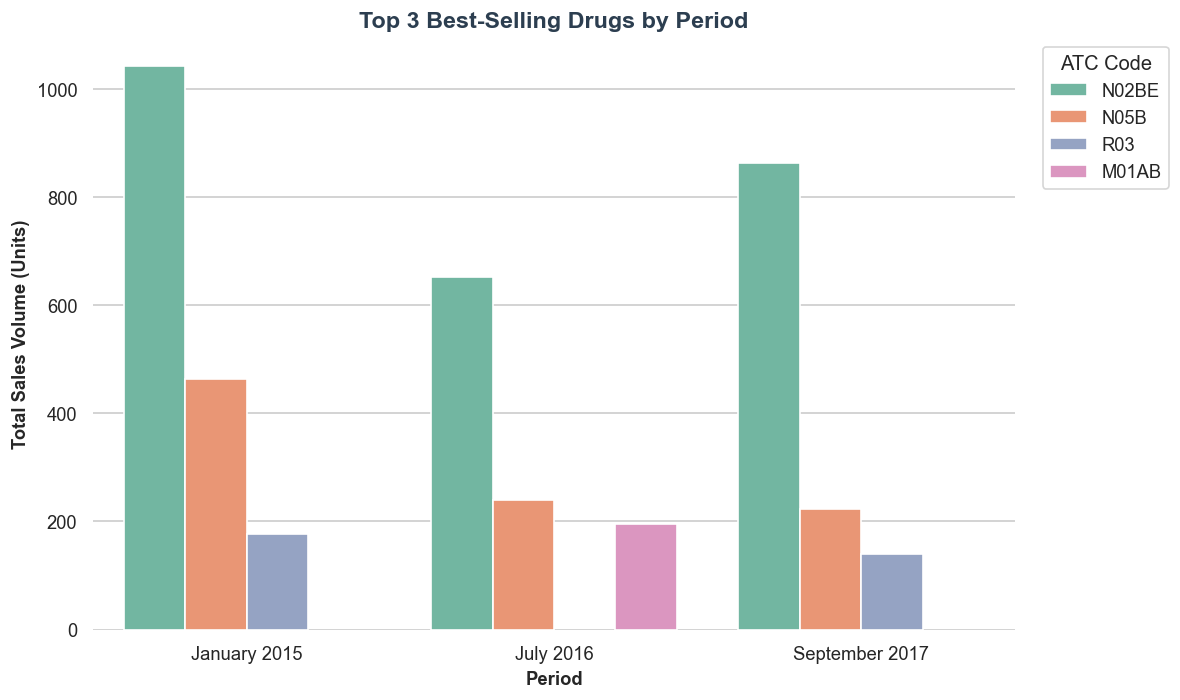

In [5]:
# ATC drug columns
drug_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Target periods
target_periods = [
    (2015, 1, "January 2015"),
    (2016, 7, "July 2016"),
    (2017, 9, "September 2017")
]

results = []

for year, month, period_name in target_periods:
    period_data = pharma[
        (pharma["Year"] == year) &
        (pharma["Month"] == month)
    ]

    # Total sales of each ATC category during the period
    sales = (
        period_data[drug_columns]
        .sum()
        .sort_values(ascending=False)
        .head(3)
    )

    print(f"\nTop three drugs in {period_name}:")
    print(sales.round(2))

    for rank, (drug, quantity) in enumerate(sales.items(), start=1):
        results.append({
            "Period": period_name,
            "Rank": rank,
            "Drug_ATC": drug,
            "Total_Sales": round(quantity, 2)
        })

top_three = pd.DataFrame(results)
display(top_three)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6), dpi=120)
sns.barplot(
    data=top_three,
    x='Period',
    y='Total_Sales',
    hue='Drug_ATC',
    palette='Set2'
)

plt.title('Top 3 Best-Selling Drugs by Period', fontsize=14, weight='bold', color='#2c3e50')
plt.xlabel('Period', fontsize=11, weight='bold')
plt.ylabel('Total Sales Volume (Units)', fontsize=11, weight='bold')
plt.legend(title='ATC Code', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


### تحلیل
با مقایسه‌ی سه دوره‌ی زمانی، دو الگوی واضح مشاهده می‌شود:

- **N02BE** و **N05B** به‌طور مداوم و بدون استثنا، رتبه‌ی اول و دوم پرفروش‌ترین داروها را در هر سه بازه
  (ژانویه 2015، ژوئیه 2016، سپتامبر 2017) به خود اختصاص داده‌اند. این ثبات نشان‌دهنده‌ی تقاضای پایدار
  و مستقل از فصل برای این دو دسته دارویی است — کاملاً هم‌راستا با نتیجه‌ی بخش ۱ که همین دو دارو را
  به‌عنوان پرفروش‌ترین‌های کل دوره معرفی کرد.

- رتبه‌ی سوم اما ثابت نیست: **R03** در ژانویه 2015 و سپتامبر 2017 (هر دو نزدیک به فصل سرد/شروع مدارس)
  در جایگاه سوم قرار گرفته، در حالی که در ژوئیه 2016 (وسط تابستان) جای خود را به **M01AB** (ضدالتهاب)
  داده است. این جایگزینی دقیقاً با انتظار فصلی هم‌خوانی دارد: R03 که برای بیماری‌های تنفسی استفاده
  می‌شود، در ماه‌های گرم سال تقاضای کمتری دارد و جای خود را به دسته‌ی دیگری می‌دهد.

این الگو نشان می‌دهد در حالی که دو دارو پرمصرف اصلی (N02BE و N05B) تقاضای باثباتی در طول سال دارند،
رتبه‌ی سوم به‌شدت تحت تأثیر فصل قرار می‌گیرد — یافته‌ای که با تحلیل فصلی heatmap در بخش ۵ نیز باید
هم‌خوانی داشته باشد.

<h3> 3.Which drug has sold most often on Mondays in 2017? </h3>

N02BE    1160.560000
N05B      320.583333
R03       267.458333
M01AB     243.496667
N02BA     170.541667
M01AE     161.875000
R06       134.925000
N05C       30.458333
dtype: float64

Drug with the highest sales: N02BE
Total sales: 1160.56


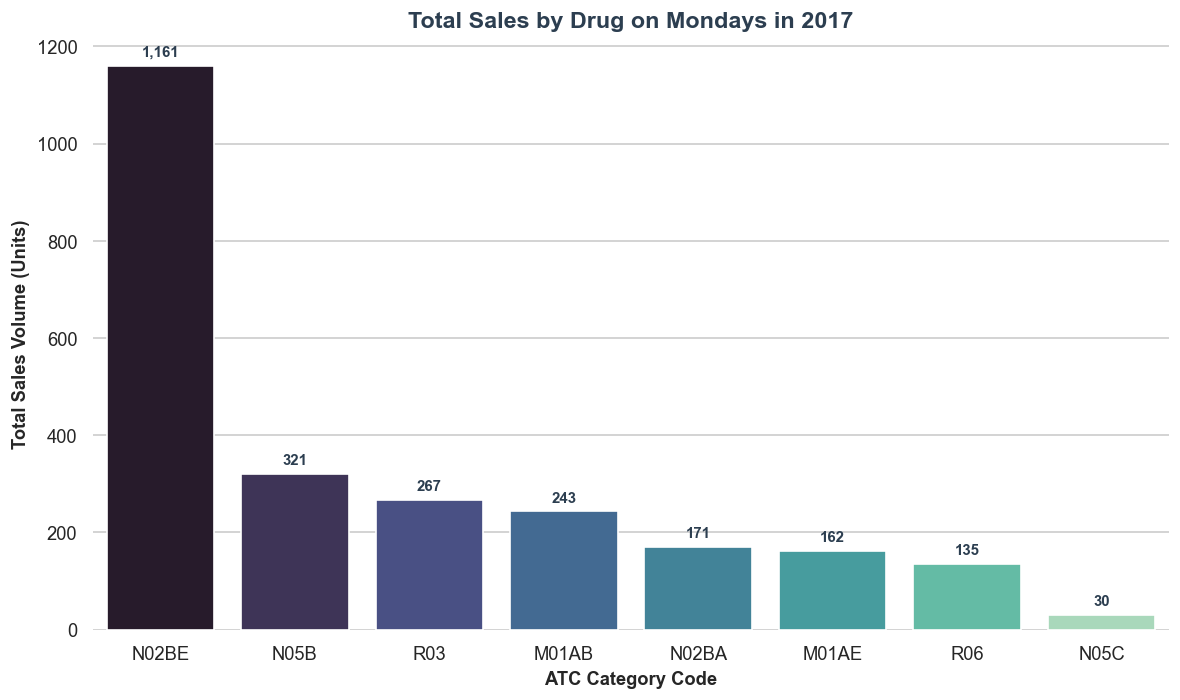

In [6]:
drug_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

monday_2017 = pharma[
    (pharma["Year"] == 2017) &
    (pharma["Weekday Name"].str.strip().str.lower() == "monday")
]

monday_sales = (
    monday_2017[drug_columns]
    .sum()
    .sort_values(ascending=False)
)

print(monday_sales)
print(f"\nDrug with the highest sales: {monday_sales.index[0]}")
print(f"Total sales: {monday_sales.iloc[0]:.2f}")


plt.figure(figsize=(10, 6), dpi=120)
monday_df = monday_sales.reset_index()
monday_df.columns = ['ATC_Code', 'Total_Sales']

barplot = sns.barplot(
    x='ATC_Code',
    y='Total_Sales',
    data=monday_df,
    palette='mako',
    hue='ATC_Code',
    legend=False
)

for p in barplot.patches:
    barplot.annotate(
        format(p.get_height(), ',.0f'),
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center', xytext=(0, 8),
        textcoords='offset points', fontsize=9, weight='bold', color='#2c3e50'
    )

plt.title('Total Sales by Drug on Mondays in 2017', fontsize=14, weight='bold', color='#2c3e50')
plt.xlabel('ATC Category Code', fontsize=11, weight='bold')
plt.ylabel('Total Sales Volume (Units)', fontsize=11, weight='bold')
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


### تحلیل
دارو **N02BE** با فروش **1,160.56** واحد، بیشترین فروش را در دوشنبه‌های سال 2017 داشته است. با توجه
به اینکه همین دارو در تحلیل بخش ۱ (کل دوره) و بخش ۲ (تمام سه ماه بررسی‌شده) نیز به‌طور مداوم پرفروش‌ترین
دسته بوده، این نتیجه بیشتر بازتاب **تسلط کلی و پایدار N02BE بر کل بازه‌ی زمانی** است تا یک الگوی خاص
مرتبط با روز دوشنبه. به عبارت دیگر، اگر به‌جای دوشنبه هر روز دیگری از هفته را بررسی می‌کردیم، به احتمال
زیاد باز هم N02BE در رتبه‌ی اول قرار می‌گرفت.

نکته‌ی جالب‌توجه‌تر، ترتیب رتبه‌ها در دوشنبه‌هاست که دقیقاً با رتبه‌بندی کلی سال‌های 2014-2019 (بخش ۱)
یکسان است: N02BE، N05B، R03، M01AB، N02BA، M01AE، R06 و N05C به همان ترتیب. این هم‌خوانی کامل نشان
می‌دهد که روز هفته (حداقل برای دوشنبه) عامل تمایزدهنده‌ی قابل‌توجهی در الگوی مصرف دارو نیست، و رتبه‌بندی
داروها بیشتر یک ویژگی ذاتی و پایدار هر دسته دارویی است تا یک الگوی وابسته به زمان.

<h3> 4. Overall sales trend over time (2014-2019) </h3>

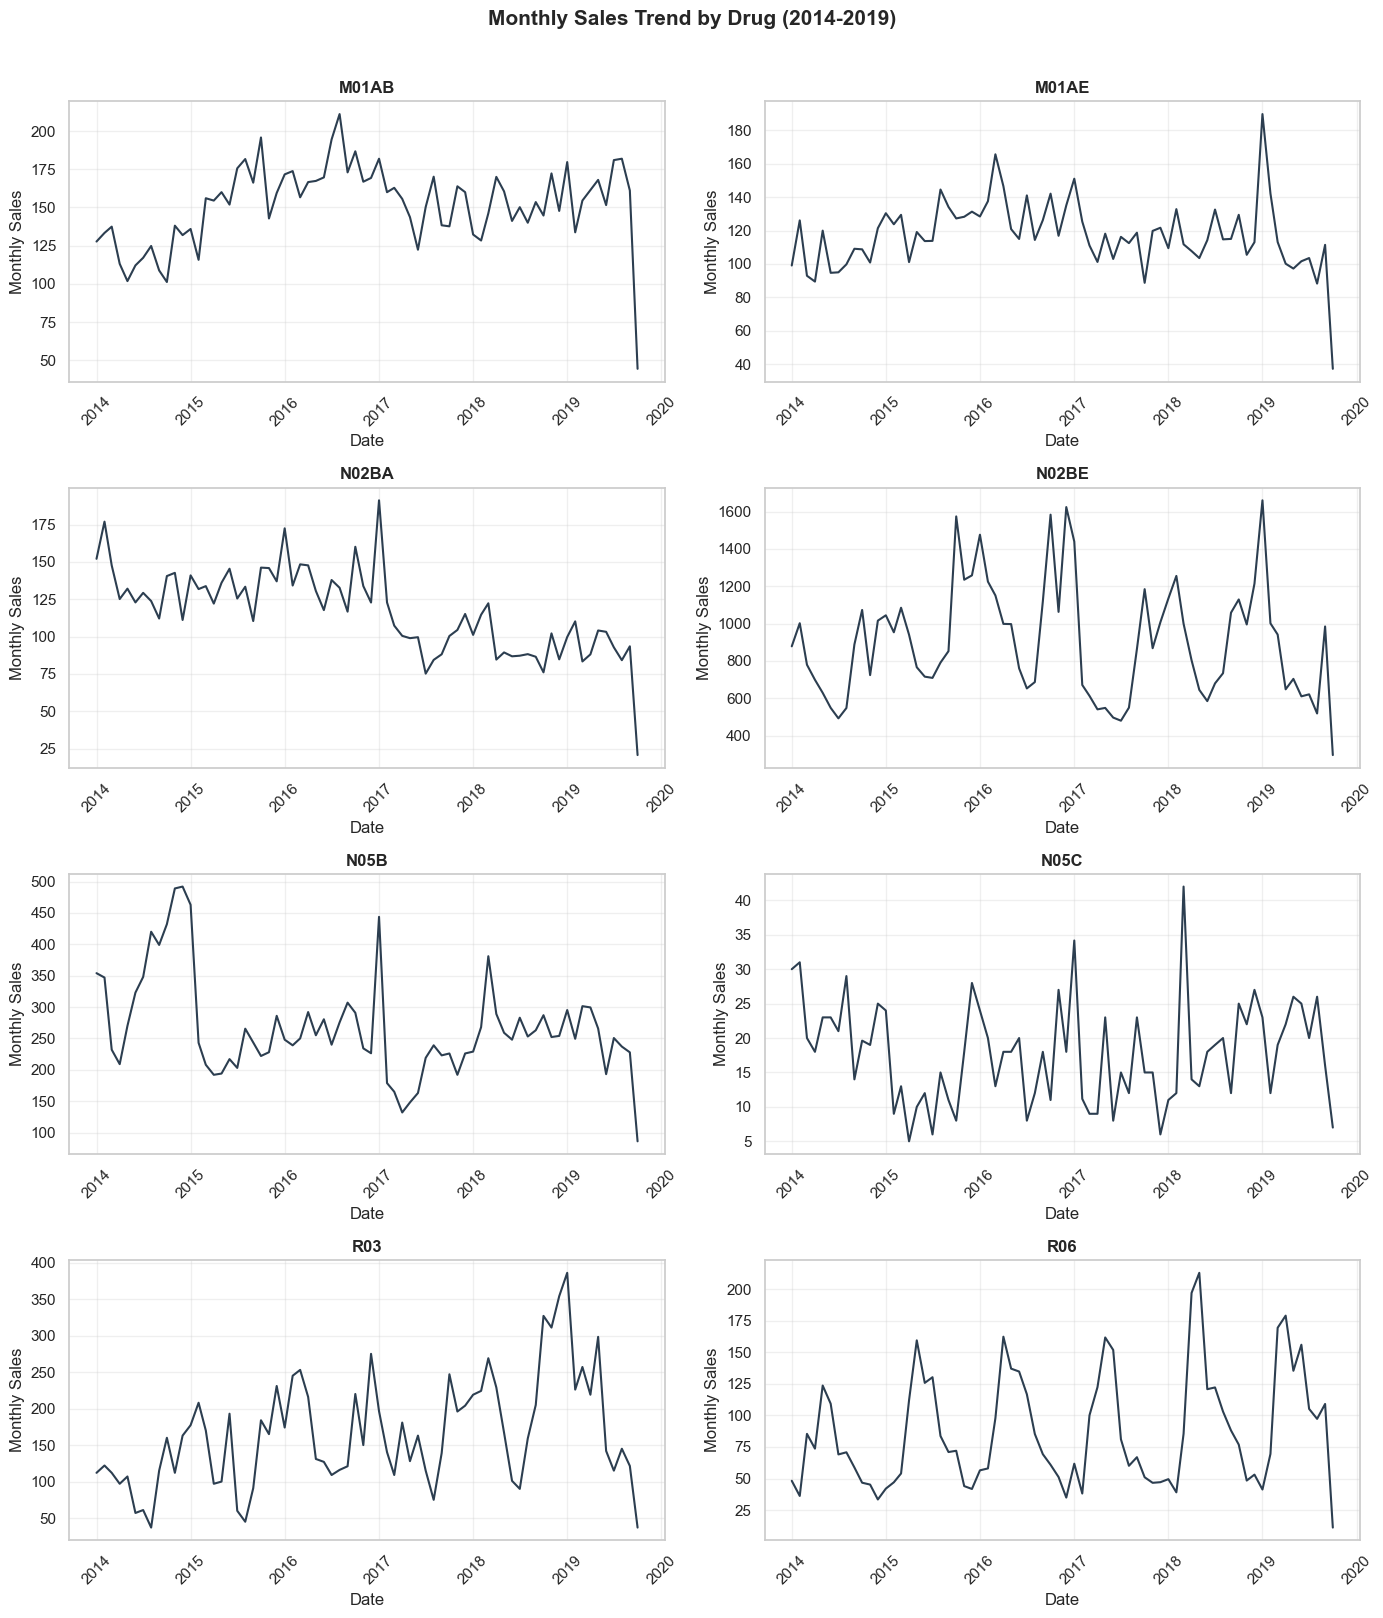

In [7]:
monthly_total = (
    pharma
    .groupby(["Year", "Month"])[drug_columns]
    .sum()
    .reset_index()
)

monthly_total["Date"] = pd.to_datetime(
    monthly_total[["Year", "Month"]].assign(DAY=1)
)

fig, axes = plt.subplots(4, 2, figsize=(14, 16), dpi=100)
axes = axes.flatten()

for i, drug in enumerate(drug_columns):
    axes[i].plot(monthly_total["Date"], monthly_total[drug], color='#2c3e50', linewidth=1.5)
    axes[i].set_title(drug, weight='bold')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Monthly Sales')
    axes[i].grid(alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Monthly Sales Trend by Drug (2014-2019)', fontsize=15, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

### تحلیل
این نمودارها روند فروش ماهانه‌ی هر دارو را از سال 2014 تا 2019 نشان می‌دهند. با نگاه به هر نمودار
می‌توان دید که آیا فروش آن دارو در طول زمان **افزایشی**، **کاهشی** یا **بدون روند مشخص (نسبتاً ثابت)**
بوده است. همچنین نوسانات تکرارشونده در هر نمودار (بالا و پایین رفتن‌های منظم در طول هر سال) نشان‌دهنده‌ی
وجود یک **الگوی فصلی** در فروش است، که در بخش بعدی (heatmap) با جزئیات بیشتری بررسی می‌شود.

<h3> 5. Seasonal pattern heatmap (Month × Year) </h3>

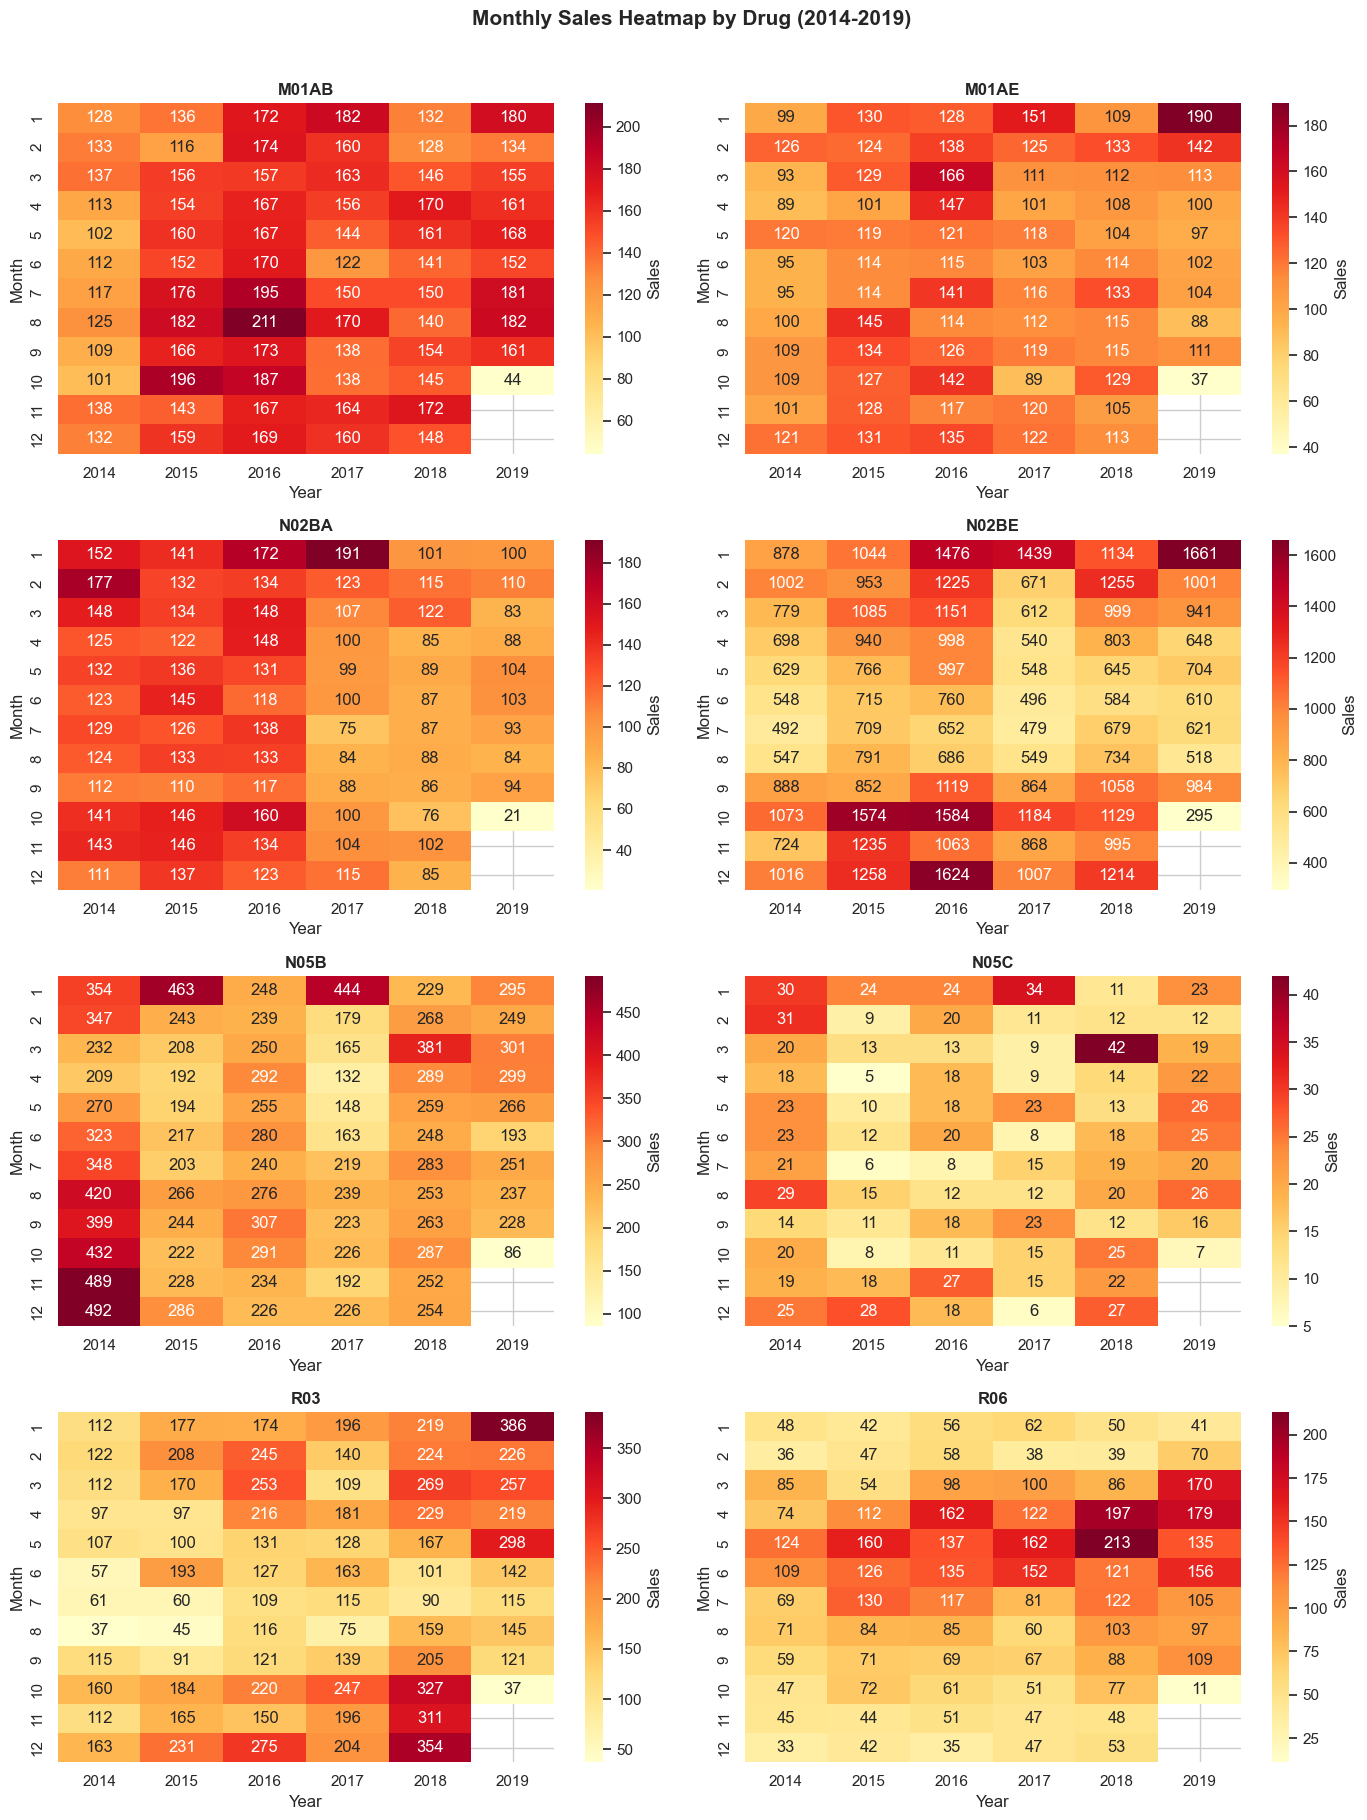

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18), dpi=100)
axes = axes.flatten()

for i, drug in enumerate(drug_columns):
    pivot = monthly_total.pivot(index="Month", columns="Year", values=drug)
    sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[i], cbar_kws={'label': 'Sales'})
    axes[i].set_title(drug, weight='bold')
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Month')

plt.suptitle('Monthly Sales Heatmap by Drug (2014-2019)', fontsize=15, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

### تحلیل
هیت‌مپ فروش ماهانه الگوی فصلی مشخصی را برای دو داروی اصلی نشان می‌دهد:

- **R03 (داروهای تنفسی):** فروش این دارو در **فصل سوم سال (ماه‌های ۷ تا ۹، تابستان)** کاهش پیدا می‌کند
  و در **فصل آخر (ماه‌های ۱۰ تا ۱۲، زمستان)** به‌طور محسوسی افزایش می‌یابد. این الگو کاملاً با انتظار
  بالینی هم‌خوانی دارد، چرا که بیماری‌های تنفسی معمولاً در فصل سرد سال شیوع بیشتری دارند و در ماه‌های
  گرم تابستان کاهش می‌یابند.

- **N02BE (مسکن‌ها):** فروش این دارو نیز در **فصل آخر سال (زمستان)** و تا حدی در **فصل اول (بهار)**
  افزایش نشان می‌دهد. این می‌تواند به دلیل هم‌زمانی با فصل سرماخوردگی و آنفلوانزا باشد، که معمولاً با
  مصرف مسکن و ضدتب همراه است.

نکته‌ی قابل‌توجه این است که هر دو دارو الگوی فصلی مشابهی (افزایش در زمستان) دارند، که با نتیجه‌ی
بخش ۲ نیز هم‌خوانی دارد — جایی که دیدیم N02BE و N05B در تمام سه ماه بررسی‌شده رتبه‌ی اول و دوم را
حفظ کردند، در حالی که R03 فقط در ماه‌های سرد سال (ژانویه، سپتامبر) در رتبه‌ی سوم ظاهر شد و در تابستان
(ژوئیه) این جایگاه را به دارویی دیگر داد.

این الگوی تکرارشونده‌ی فصلی، توجیه مستقیمی برای استفاده از فیچرهای `month_sin` و `month_cos` در
مدل رگرسیون خطی (بخش پیش‌بینی) است — بدون این فیچرها، مدل نمی‌توانست این نوسان چرخه‌ای سالانه را
شناسایی کند.

<h3> 6. Correlation between drug categories </h3>

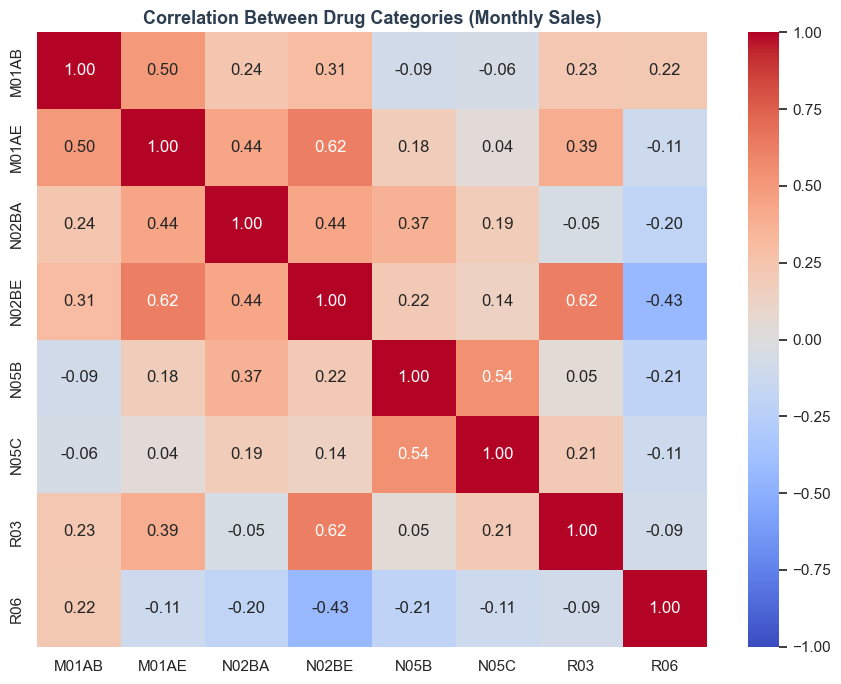

In [9]:
corr_matrix = monthly_total[drug_columns].corr()

plt.figure(figsize=(9, 7), dpi=100)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title('Correlation Between Drug Categories (Monthly Sales)', fontsize=13, weight='bold', color='#2c3e50')
plt.tight_layout()
plt.show()

### تحلیل
بالاترین همبستگی مشاهده‌شده مربوط به جفت **N02BE و R03** با ضریب **0.62** است. این مقدار در محدوده‌ی
همبستگی **متوسط** قرار دارد — یعنی روند فروش این دو دارو تا حدی هم‌جهت است، اما رابطه‌ی قوی یا قطعی
بین آن‌ها وجود ندارد. این همبستگی می‌تواند بازتاب الگوی فصلی مشترکی باشد که در بخش ۵ مشاهده کردیم:
هر دو دارو در فصل زمستان افزایش فروش دارند (R03 به‌دلیل بیماری‌های تنفسی و N02BE به‌دلیل تب و درد
همراه با سرماخوردگی)، که باعث می‌شود نوسانات ماهانه‌شان تا حدی با هم هم‌راستا باشد.

دومین همبستگی بالا، بین **M01AE و N02BE** با ضریب **0.62**، نیز مشابه است — احتمالاً به این دلیل که
هر دو دارو (ضدالتهاب و مسکن) در شرایط درد یا التهاب هم‌زمان تجویز و مصرف می‌شوند.

سایر جفت‌ها (مانند N05B-N05C با 0.54، یا M01AB-M01AE با 0.50) همبستگی ضعیف‌تری دارند و بیشتر
نشان‌دهنده‌ی این هستند که دسته‌های دارویی مختلف عمدتاً **مستقل از هم** و متأثر از عوامل خاص خودشان
عمل می‌کنند، نه یک محرک واحد در سطح کل داروخانه.

از منظر کاربردی، این یافته می‌تواند برای مدیریت موجودی داروخانه مفید باشد: افزایش تقاضا برای R03
می‌تواند نشانه‌ای زودهنگام برای افزایش احتمالی تقاضای N02BE (و بالعکس) باشد، به‌ویژه در فصل‌های سرد سال.

<h3> Backtesting: Multi-fold validation for Linear Regression </h3>

In [17]:
backtest_folds = [
    (list(range(2014, 2017)), 2017),  # train 2014-2016, test 2017
    (list(range(2014, 2018)), 2018),  # train 2014-2017, test 2018
    (list(range(2014, 2019)), 2019),  # train 2014-2018, test 2019
]

backtest_results = []

for train_years, test_year in backtest_folds:
    train_fold = monthly_sales[monthly_sales["Year"].isin(train_years)].copy()
    test_fold = monthly_sales[monthly_sales["Year"] == test_year].copy()

    for drug in drug_columns:
        X_train = train_fold[features]
        y_train = train_fold[drug]

        X_test = test_fold[features]
        y_test = test_fold[drug]

        model = LinearRegression()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        mae = np.mean(np.abs(y_test.values - y_pred))
        rmse = np.sqrt(np.mean((y_test.values - y_pred) ** 2))
        mape = np.mean(
            np.abs((y_test.values - y_pred) / np.where(y_test.values == 0, np.nan, y_test.values))
        ) * 100

        backtest_results.append({
            "Fold": f"Train {train_years[0]}-{train_years[-1]} → Test {test_year}",
            "Test_Year": test_year,
            "Medicine_ATC": drug,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "MAPE_percent": round(mape, 2)
        })

backtest_df = pd.DataFrame(backtest_results)

print("Backtesting Results Across Folds")
display(backtest_df)

Backtesting Results Across Folds


,Fold,Test_Year,Medicine_ATC,MAE,RMSE,MAPE_percent
0,Train 2014-2016 → Test 2017,2017,M01AB,52.51,55.77,35.74
1,Train 2014-2016 → Test 2017,2017,M01AE,32.73,35.35,30.16
2,Train 2014-2016 → Test 2017,2017,N02BA,36.85,38.00,37.38
3,Train 2014-2016 → Test 2017,2017,N02BE,526.12,561.05,81.92
4,Train 2014-2016 → Test 2017,2017,N05B,34.59,65.76,12.43
5,Train 2014-2016 → Test 2017,2017,N05C,6.28,8.22,43.30
6,Train 2014-2016 → Test 2017,2017,R03,63.14,71.71,47.98
7,Train 2014-2016 → Test 2017,2017,R06,22.89,28.54,38.13
8,Train 2014-2017 → Test 2018,2018,M01AB,32.48,35.38,22.74
9,Train 2014-2017 → Test 2018,2018,M01AE,15.15,17.39,13.67


Backtesting Summary (Mean & Std across folds)


,Medicine_ATC,Mean_RMSE,Std_RMSE,Mean_MAPE,Std_MAPE
0,N05C,9.36,1.99,42.96,0.29
1,N02BA,27.28,9.81,32.92,13.25
2,M01AE,29.95,10.92,27.97,13.34
3,R06,30.96,2.14,43.87,25.06
4,M01AB,44.50,10.36,31.32,7.43
5,R03,74.35,17.29,51.31,31.14
6,N05B,91.89,30.36,29.29,14.61
7,N02BE,321.07,234.60,43.47,37.31


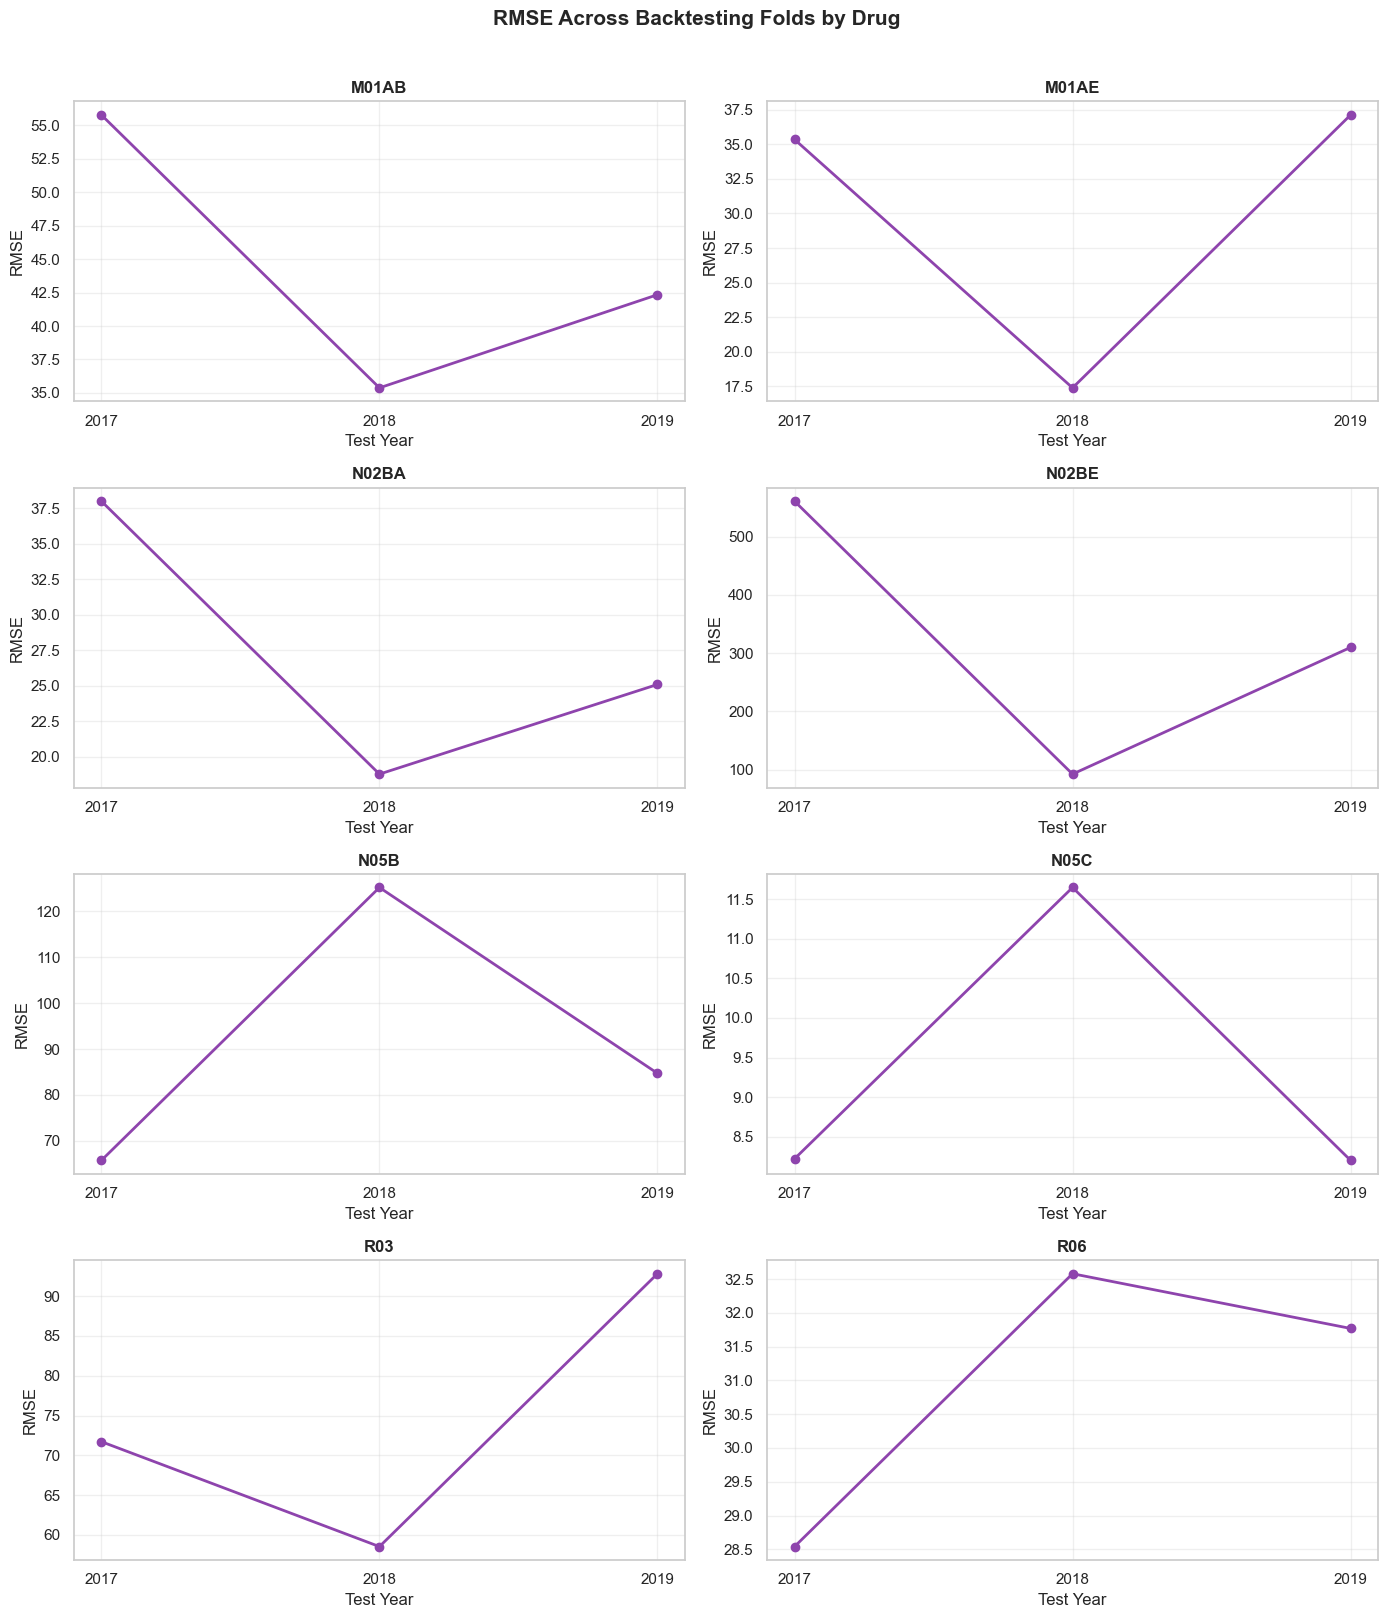

In [19]:
backtest_summary = (
    backtest_df
    .groupby("Medicine_ATC")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAPE=("MAPE_percent", "mean"),
        Std_MAPE=("MAPE_percent", "std")
    )
    .round(2)
    .sort_values("Mean_RMSE")
    .reset_index()
)

print("Backtesting Summary (Mean & Std across folds)")
display(backtest_summary)


fig, axes = plt.subplots(4, 2, figsize=(14, 16), dpi=100)
axes = axes.flatten()

fold_order = [f"Train {tr[0]}-{tr[-1]} → Test {ty}" for tr, ty in backtest_folds]

for i, drug in enumerate(drug_columns):
    drug_data = backtest_df[backtest_df["Medicine_ATC"] == drug].set_index("Fold").loc[fold_order]
    axes[i].plot(drug_data["Test_Year"], drug_data["RMSE"], marker='o', color='#8e44ad', linewidth=2)
    axes[i].set_title(drug, weight='bold')
    axes[i].set_xlabel('Test Year')
    axes[i].set_ylabel('RMSE')
    axes[i].set_xticks(drug_data["Test_Year"])
    axes[i].grid(alpha=0.3)

plt.suptitle('RMSE Across Backtesting Folds by Drug', fontsize=15, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

### تحلیل
نتایج backtesting سه‌فولدی، تصویر دقیق‌تری از پایداری مدل رگرسیون خطی نسبت به ارزیابی تک‌ساله‌ی
قبلی ارائه می‌دهد.

**پایدارترین دارو از نظر دقت:** **N05C** با Mean_RMSE برابر ۹.۳۶ و Std_RMSE تنها ۱.۹۹، به‌طور
مشخصی پایدارترین و قابل‌اعتمادترین پیش‌بینی را در میان تمام فولدها داشته است — یعنی مدل برای این
دارو، مستقل از اینکه کدام سال را تست کنیم، رفتار تقریباً یکسانی نشان می‌دهد.

**ناپایدارترین دارو:** **N02BE** با Mean_RMSE بسیار بالای ۳۲۱.۰۷ و Std_RMSE برابر ۲۳۴.۶۰ (بزرگ‌ترین
انحراف معیار در بین همه‌ی داروها)، نشان می‌دهد که دقت مدل برای این دارو به‌شدت به سال تست وابسته است:
RMSE آن از ۹۲.۲۵ در فولد 2018 تا ۵۶۱.۰۵ در فولد 2017 نوسان داشته — یعنی بیش از ۶ برابر تفاوت. این
ناپایداری تا حدی طبیعی است چون N02BE (طبق بخش ۱) پرفروش‌ترین و بزرگ‌ترین‌مقیاس دارو است، و مدل‌های
خطی روی مقادیر بزرگ‌تر معمولاً خطای مطلق بزرگ‌تری هم تولید می‌کنند.

**رفتار غیرمنتظره در طول فولدها:** برخلاف انتظار اولیه که افزایش داده‌ی آموزشی (از فولد ۲۰۱۷ به ۲۰۱۹)
باید باعث بهبود تدریجی دقت شود، این روند برای بیشتر داروها مشاهده نمی‌شود. برای مثال RMSE داروی
M01AE از ۳۵.۳۵ (فولد 2017) به ۱۷.۳۹ (فولد 2018) کاهش یافت، اما دوباره به ۳۷.۱۲ در فولد 2019 افزایش
پیدا کرد. الگوی مشابهی برای M01AB، N02BA، N02BE و R03 نیز دیده می‌شود. این نشان می‌دهد که **حجم
داده‌ی آموزشی به‌تنهایی تضمین‌کننده‌ی بهبود دقت نیست**؛ در عوض، میزان نوسان‌پذیری ذاتی هر سال (که
احتمالاً از عوامل بیرونی مانند شیوع فصلی بیماری‌ها یا تغییرات تقاضا ناشی می‌شود) نقش مهم‌تری در
دقت پیش‌بینی آن سال دارد. به‌طور خاص، سال ۲۰۱۹ برای اکثر داروها (به‌جز N05C) بدترین یا نزدیک به
بدترین MAPE را در میان سه فولد داشته، که نشان می‌دهد ۲۰۱۹ سال نسبتاً غیرمعمولی از نظر الگوی فروش
بوده است.

**نتیجه‌گیری کلی:** ارزیابی مدل تنها بر پایه‌ی یک سال تست (مانند آنچه در تحلیل اولیه روی 2019 انجام
شد) می‌تواند تصویر ناقص یا حتی گمراه‌کننده‌ای از عملکرد واقعی مدل ارائه دهد. برای مثال، اگر فقط فولد
2018 را در نظر می‌گرفتیم، دقت مدل روی M01AE یا N02BE بسیار بهتر از واقعیت به‌نظر می‌رسید. استفاده
از میانگین و انحراف معیار چندفولدی، معیار واقع‌بینانه‌تری برای اعتماد به این مدل در کاربرد عملی
(مانند برنامه‌ریزی موجودی داروخانه) فراهم می‌کند.

<h3> Backtesting: Multi-fold validation for Holt-Winters </h3>

In [20]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

backtest_folds = [
    (list(range(2014, 2017)), 2017),  # train 2014-2016, test 2017
    (list(range(2014, 2018)), 2018),  # train 2014-2017, test 2018
    (list(range(2014, 2019)), 2019),  # train 2014-2018, test 2019
]

backtest_results_hw = []

for train_years, test_year in backtest_folds:
    train_fold = monthly_sales_full[monthly_sales_full["Year"].isin(train_years)].copy()
    test_fold = monthly_sales_full[monthly_sales_full["Year"] == test_year].copy()

    for drug in drug_columns:
        train_series = train_fold.set_index("Date")[drug]
        test_series = test_fold.set_index("Date")[drug]

        model = ExponentialSmoothing(
            train_series,
            trend="add",
            seasonal="add",
            seasonal_periods=12
        ).fit(optimized=True)

        forecast = model.forecast(steps=len(test_series))

        actual_values = test_series.values
        predicted_values = forecast.values

        mae = np.mean(np.abs(actual_values - predicted_values))
        rmse = np.sqrt(np.mean((actual_values - predicted_values) ** 2))
        mape = np.nanmean(
            np.abs(
                (actual_values - predicted_values) /
                np.where(actual_values == 0, np.nan, actual_values)
            )
        ) * 100

        backtest_results_hw.append({
            "Fold": f"Train {train_years[0]}-{train_years[-1]} → Test {test_year}",
            "Test_Year": test_year,
            "Medicine_ATC": drug,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "MAPE_percent": round(mape, 2)
        })

backtest_df_hw = pd.DataFrame(backtest_results_hw)

print("Backtesting Results Across Folds (Holt-Winters)")
display(backtest_df_hw)

c:\Users\14386\Desktop\Analysing-pharmaceutical-sales-data\.venv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\14386\Desktop\Analysing-pharmaceutical-sales-data\.venv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\14386\Desktop\Analysing-pharmaceutical-sales-data\.venv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\14386\Desktop\Analysing-pharmaceutical-sales-data\.venv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\14386\D

Backtesting Results Across Folds (Holt-Winters)


,Fold,Test_Year,Medicine_ATC,MAE,RMSE,MAPE_percent
0,Train 2014-2016 → Test 2017,2017,M01AB,35.78,39.65,24.50
1,Train 2014-2016 → Test 2017,2017,M01AE,33.40,36.05,30.65
2,Train 2014-2016 → Test 2017,2017,N02BA,36.91,38.77,37.37
3,Train 2014-2016 → Test 2017,2017,N02BE,526.12,555.72,80.46
4,Train 2014-2016 → Test 2017,2017,N05B,85.74,101.19,39.37
5,Train 2014-2016 → Test 2017,2017,N05C,6.65,8.17,50.60
6,Train 2014-2016 → Test 2017,2017,R03,57.73,70.10,44.09
7,Train 2014-2016 → Test 2017,2017,R06,19.86,24.64,33.89
8,Train 2014-2017 → Test 2018,2018,M01AB,18.68,21.90,13.10
9,Train 2014-2017 → Test 2018,2018,M01AE,17.41,20.76,14.56


In [21]:
backtest_summary_hw = (
    backtest_df_hw
    .groupby("Medicine_ATC")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAPE=("MAPE_percent", "mean"),
        Std_MAPE=("MAPE_percent", "std")
    )
    .round(2)
    .sort_values("Mean_RMSE")
    .reset_index()
)

print("Backtesting Summary - Holt-Winters (Mean & Std across folds)")
display(backtest_summary_hw)

Backtesting Summary - Holt-Winters (Mean & Std across folds)


,Medicine_ATC,Mean_RMSE,Std_RMSE,Mean_MAPE,Std_MAPE
0,N05C,11.18,3.25,47.43,8.76
1,N02BA,31.71,14.68,32.22,19.12
2,R06,32.39,9.22,45.64,34.15
3,M01AE,38.43,18.97,26.97,11.04
4,M01AB,45.13,26.41,23.23,9.56
5,R03,104.54,69.63,66.89,56.75
6,N05B,119.80,18.04,38.44,4.81
7,N02BE,452.94,193.93,49.73,29.29


### تحلیل
نتایج backtesting سه‌فولدی برای Holt-Winters نیز الگوی مشابهی از **ناپایداری بین سال‌ها** را نشان
می‌دهد، اما با شدت بیشتر نسبت به رگرسیون خطی.

**پایدارترین دارو:** همانند رگرسیون خطی، **N05C** پایدارترین دارو از نظر دقت است (Mean_RMSE=۱۱.۱۸،
Std_RMSE=۳.۲۵)، اگرچه هم میانگین خطا و هم انحراف معیارش نسبت به مدل رگرسیون خطی (RMSE=۹.۳۶،
Std=۱.۹۹) کمی بالاتر است.

**ناپایدارترین دارو:** **N02BE** با Mean_RMSE بسیار بالای ۴۵۲.۹۴ و Std_RMSE برابر ۱۹۳.۹۳، بازهم
بی‌ثبات‌ترین پیش‌بینی را دارد — RMSE آن از ۲۲۹.۲۵ در فولد ۲۰۱۸ تا ۵۷۳.۸۴ در فولد ۲۰۱۹ نوسان کرده،
که نشان می‌دهد بزرگ بودن مقیاس فروش این دارو مستقل از نوع مدل (خطی یا Holt-Winters)، همچنان چالش
اصلی برای هر دو روش است.

**نکته‌ی قابل‌توجه: R03.** برخلاف رگرسیون خطی که برای R03 ثبات نسبی داشت، در مدل Holt-Winters این
دارو یکی از بی‌ثبات‌ترین‌ها شده است (Std_RMSE=۶۹.۶۳، تقریباً ۴ برابر بیشتر از رگرسیون خطی). به‌طور
خاص، MAPE این دارو در فولد ۲۰۱۹ به ۱۳۱.۴۹٪ رسیده — بسیار بالاتر از دو فولد دیگر (۴۴.۰۹٪ و ۲۵.۰۹٪).
این جهش شدید می‌تواند نشان‌دهنده‌ی این باشد که مدل Holt-Winters با تنها داده‌ی محدود (فولدهای کوچک‌تر)
در تخمین پارامترهای فصلی این دارو با نوسان شدید، دچار بی‌ثباتی بیشتری نسبت به رگرسیون خطی می‌شود.

**مقایسه‌ی مستقیم با رگرسیون خطی:** با کنار هم گذاشتن دو جدول خلاصه، مشخص می‌شود که مدل **رگرسیون
خطی در تمام هشت دارو، Mean_RMSE پایین‌تری نسبت به Holt-Winters دارد** — از تفاوت اندک در M01AB
(۴۴.۵۰ در برابر ۴۵.۱۳) تا تفاوت بزرگ در N02BE (۳۲۱.۰۷ در برابر ۴۵۲.۹۴) و R03 (۷۴.۳۵ در برابر
۱۰۴.۵۴). این نتیجه با ارزیابی اولیه (تک‌ساله، فقط 2019) کاملاً هم‌راستا است و اعتبار بیشتری به آن
نتیجه‌گیری می‌دهد: در اینجا برخلاف ارزیابی تک‌فولدی، دیگر نمی‌توان این برتری را به یک سال خاص یا
شانس نسبت داد، چون این برتری در **همه‌ی سه فولد و همه‌ی هشت دارو** به‌طور مداوم تکرار شده است.

**نتیجه‌گیری کلی:** با وجود اینکه Holt-Winters از نظر تئوری روش پیچیده‌تر و مناسب‌تری برای داده‌ی
فصلی به‌نظر می‌رسد، در عمل و با این حجم داده (۳ تا ۶ سال، یعنی حداکثر ۶ دوره‌ی کامل فصلی)، رگرسیون
خطی با فیچرهای دستی (`time_index`, `month_sin`, `month_cos`) عملکرد پایدارتر و دقیق‌تری ارائه داده
است. این می‌تواند به این دلیل باشد که تخمین سه پارامتر (level, trend, seasonal) در Holt-Winters
به داده‌ی بیشتری برای پایداری نیاز دارد، در حالی که رگرسیون خطی با فرض ساده‌تر خود کمتر در معرض
overfitting روی نوسانات کوتاه‌مدت هر فولد قرار می‌گیرد.

<h3> Comparison of two methods </h3>

,Medicine_ATC,Mean_RMSE_LR,Mean_RMSE_HW,Std_RMSE_LR,Std_RMSE_HW,Mean_MAPE_LR,Mean_MAPE_HW,Better_Model
0,M01AB,44.50,45.13,10.36,26.41,31.32,23.23,Linear Regression
1,M01AE,29.95,38.43,10.92,18.97,27.97,26.97,Linear Regression
2,N02BA,27.28,31.71,9.81,14.68,32.92,32.22,Linear Regression
3,N02BE,321.07,452.94,234.60,193.93,43.47,49.73,Linear Regression
4,N05B,91.89,119.80,30.36,18.04,29.29,38.44,Linear Regression
5,N05C,9.36,11.18,1.99,3.25,42.96,47.43,Linear Regression
6,R03,74.35,104.54,17.29,69.63,51.31,66.89,Linear Regression
7,R06,30.96,32.39,2.14,9.22,43.87,45.64,Linear Regression


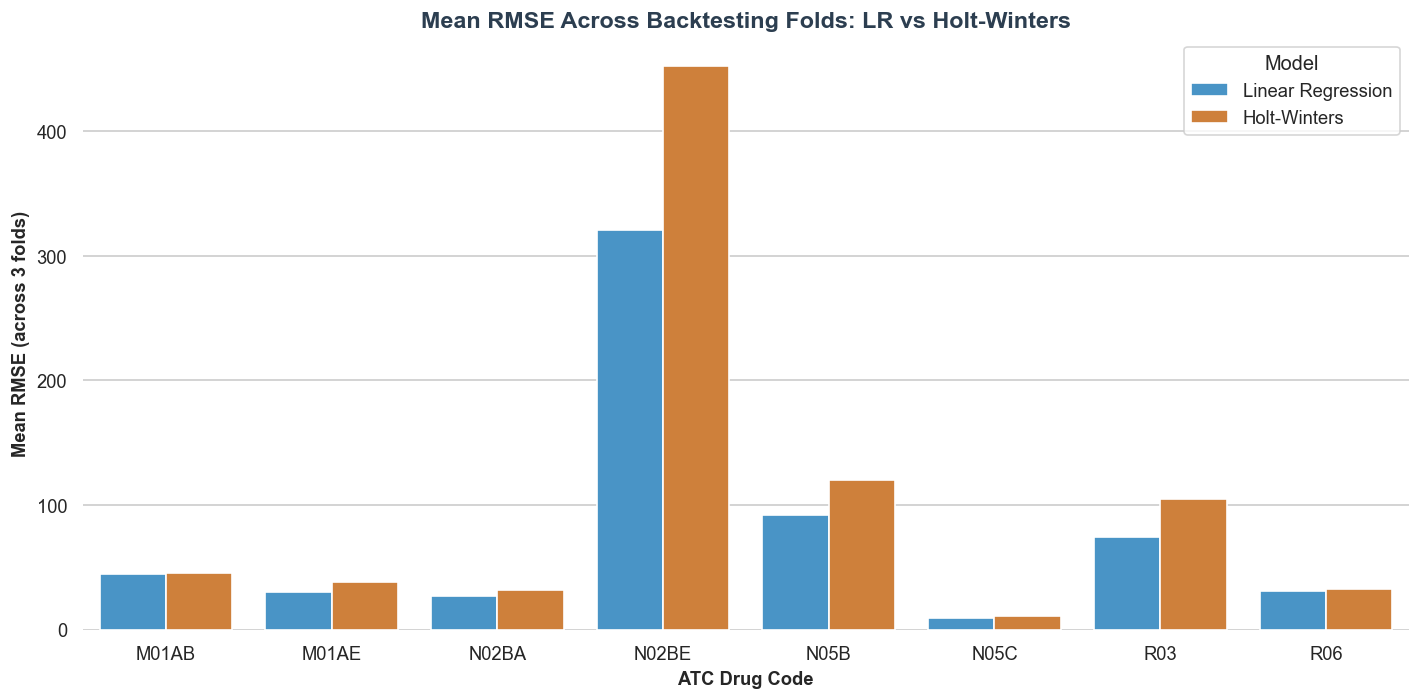

In [23]:
backtest_comparison = (
    backtest_summary
    .merge(backtest_summary_hw, on="Medicine_ATC", suffixes=("_LR", "_HW"))
)

backtest_comparison["Better_Model"] = np.where(
    backtest_comparison["Mean_RMSE_HW"] < backtest_comparison["Mean_RMSE_LR"],
    "Holt-Winters",
    np.where(
        backtest_comparison["Mean_RMSE_LR"] < backtest_comparison["Mean_RMSE_HW"],
        "Linear Regression",
        "Tie"
    )
)

backtest_comparison = backtest_comparison[[
    "Medicine_ATC",
    "Mean_RMSE_LR", "Mean_RMSE_HW",
    "Std_RMSE_LR", "Std_RMSE_HW",
    "Mean_MAPE_LR", "Mean_MAPE_HW",
    "Better_Model"
]].sort_values("Medicine_ATC").reset_index(drop=True)

display(backtest_comparison)


comparison_melted = backtest_comparison.melt(
    id_vars="Medicine_ATC",
    value_vars=["Mean_RMSE_LR", "Mean_RMSE_HW"],
    var_name="Model",
    value_name="Mean_RMSE"
)
comparison_melted["Model"] = comparison_melted["Model"].map({
    "Mean_RMSE_LR": "Linear Regression",
    "Mean_RMSE_HW": "Holt-Winters"
})

plt.figure(figsize=(12, 6), dpi=120)
sns.barplot(data=comparison_melted, x="Medicine_ATC", y="Mean_RMSE", hue="Model", palette=["#3498db", "#e67e22"])
plt.title('Mean RMSE Across Backtesting Folds: LR vs Holt-Winters', fontsize=14, weight='bold', color='#2c3e50')
plt.xlabel('ATC Drug Code', fontsize=11, weight='bold')
plt.ylabel('Mean RMSE (across 3 folds)', fontsize=11, weight='bold')
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### تحلیل
جدول مقایسه‌ی نهایی، حاصل میانگین‌گیری از سه فولد مختلف، نتیجه‌ی روشن و بدون‌استثنایی ارائه می‌دهد:
**رگرسیون خطی در تمام هشت دسته‌ی دارویی، Mean_RMSE پایین‌تری نسبت به Holt-Winters دارد** — از تفاوت
جزئی در M01AB (۴۴.۵۰ در برابر ۴۵.۱۳، تنها ۱٪ بهتر) تا تفاوت بسیار زیاد در N02BE (۳۲۱.۰۷ در برابر
۴۵۲.۹۴، حدود ۴۱٪ بهتر) و R03 (۷۴.۳۵ در برابر ۱۰۴.۵۴، حدود ۴۱٪ بهتر).

این یافته اهمیت بالایی دارد چون **کاملاً با نتیجه‌ی ارزیابی تک‌ساله‌ی اولیه (فقط 2019) هم‌راستا است**،
اما این‌بار با شواهد قوی‌تر: برخلاف ارزیابی تک‌فولدی که می‌توانست نتیجه‌ی یک سال خاص (شانسی یا اتفاقی)
باشد، این برتری در **هر سه فولد مستقل (2017، 2018، 2019) و هر هشت دارو** به‌طور مداوم تکرار شده است.
بنابراین می‌توان با اطمینان بیشتری نتیجه گرفت که رگرسیون خطی، حداقل با ساختار فیچرهای فعلی (`time_index`,
`month_sin`, `month_cos`) و حجم داده‌ی موجود (۳ تا ۶ سال)، انتخاب قابل‌اعتمادتری نسبت به Holt-Winters
برای این دیتاست است.

نکته‌ی دوم و کمتر بدیهی، مقایسه‌ی ستون‌های **Std_RMSE** است: در پنج از هشت دارو (M01AB، M01AE، N02BE،
R03، R06)، انحراف معیار رگرسیون خطی نیز پایین‌تر از Holt-Winters است — یعنی نه‌تنها دقت آن به‌طور
میانگین بهتر است، بلکه **پایدارتر** هم هست (کمتر بین سال‌های مختلف نوسان می‌کند). استثنای قابل‌توجه
N05B است، جایی که Holt-Winters با Std_RMSE پایین‌تر (۱۸.۰۴ در برابر ۳۰.۳۶) پایداری بیشتری نشان می‌دهد،
حتی با وجود اینکه دقت میانگینش (Mean_RMSE) بدتر است.

**نتیجه‌گیری نهایی:** بر اساس این تحلیل چندفولدی، **رگرسیون خطی به‌عنوان مدل نهایی برای پیش‌بینی فروش
این دیتاست پیشنهاد می‌شود** — نه فقط به این دلیل که در ارزیابی 2019 بهتر بود، بلکه چون این برتری در
یک آزمایش قوی‌تر (سه فولد مستقل) نیز تأیید شده است. با این حال، برتری این مدل نباید مطلق تلقی شود:
هر دو مدل برای دارویی مثل **N02BE** خطای نسبتاً بزرگ و ناپایدار دارند (Std_RMSE بالا در هر دو روش)،
که نشان می‌دهد نیاز به بررسی مدل‌های جایگزین (مانند SARIMA یا مدل‌های مبتنی بر درخت با ویژگی‌های
lag) برای این دارو به‌طور خاص همچنان وجود دارد.

<h3> linear regression prediction for 2020 </h3>

In [15]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

drug_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

pharma["datum"] = pd.to_datetime(pharma["datum"])

monthly_sales = (
    pharma
    .groupby(["Year", "Month"])[drug_columns]
    .sum()
    .reset_index()
)

monthly_sales["time_index"] = (
    (monthly_sales["Year"] - monthly_sales["Year"].min()) * 12
    + monthly_sales["Month"]
)

monthly_sales["month_sin"] = np.sin(2 * np.pi * monthly_sales["Month"] / 12)
monthly_sales["month_cos"] = np.cos(2 * np.pi * monthly_sales["Month"] / 12)

features = ["time_index", "Month", "month_sin", "month_cos"]


train_data = monthly_sales[monthly_sales["Year"].between(2014, 2019)].copy()


future_2020 = pd.DataFrame({
    "Year": 2020,
    "Month": range(1, 13)
})

future_2020["time_index"] = (
    (future_2020["Year"] - monthly_sales["Year"].min()) * 12
    + future_2020["Month"]
)
future_2020["month_sin"] = np.sin(2 * np.pi * future_2020["Month"] / 12)
future_2020["month_cos"] = np.cos(2 * np.pi * future_2020["Month"] / 12)

forecast_frames = []
models = {}  

for drug in drug_columns:
    X_train = train_data[features]
    y_train = train_data[drug]

    model = LinearRegression()
    model.fit(X_train, y_train)
    models[drug] = model

    y_pred = model.predict(future_2020[features])

    drug_forecast = pd.DataFrame({
        "Year": future_2020["Year"].values,
        "Month": future_2020["Month"].values,
        "Medicine_ATC": drug,
        "Forecast_2020_Sales": np.round(y_pred, 2)
    })

    forecast_frames.append(drug_forecast)

forecast_2020 = pd.concat(forecast_frames, ignore_index=True)

print("Forecasted Monthly Sales for 2020 (No Actuals Available)")
display(forecast_2020)

Forecasted Monthly Sales for 2020 (No Actuals Available)


,Year,Month,Medicine_ATC,Forecast_2020_Sales
0,2020,1,M01AB,160.23
1,2020,2,M01AB,160.22
2,2020,3,M01AB,160.86
3,2020,4,M01AB,162.00
4,2020,5,M01AB,163.34
...,...,...,...,...
91,2020,8,R06,114.39
92,2020,9,R06,88.39
93,2020,10,R06,69.89
94,2020,11,R06,64.75


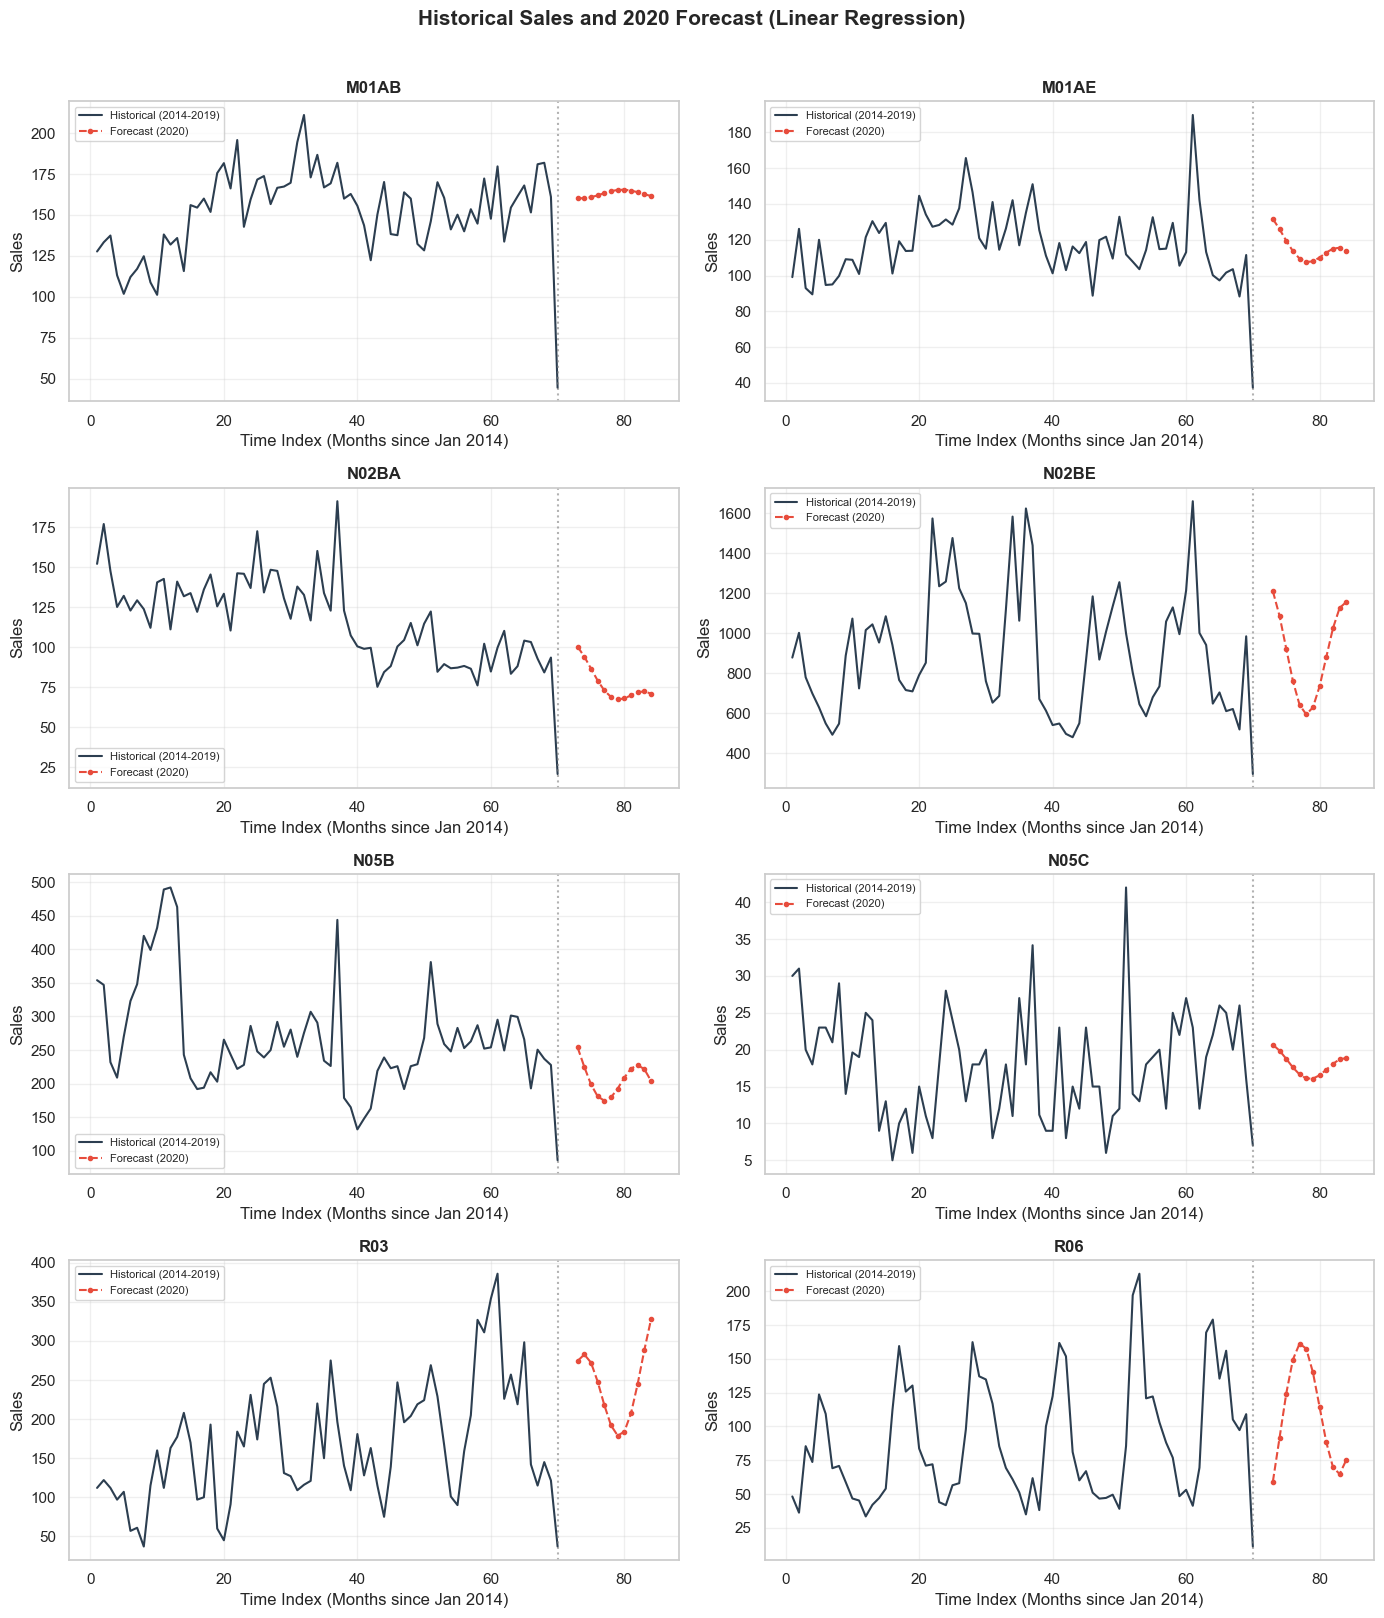

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16), dpi=100)
axes = axes.flatten()

for i, drug in enumerate(drug_columns):
    hist = monthly_sales[monthly_sales["Year"].between(2014, 2019)]
    hist_x = hist["time_index"]
    hist_y = hist[drug]

    forecast_drug = forecast_2020[forecast_2020["Medicine_ATC"] == drug]
    forecast_x = future_2020["time_index"]
    forecast_y = forecast_drug["Forecast_2020_Sales"]

    axes[i].plot(hist_x, hist_y, color='#2c3e50', label='Historical (2014-2019)')
    axes[i].plot(forecast_x, forecast_y, color='#e74c3c', linestyle='--', marker='o', markersize=3, label='Forecast (2020)')
    axes[i].axvline(x=hist_x.max(), color='gray', linestyle=':', alpha=0.6)
    axes[i].set_title(drug, weight='bold')
    axes[i].set_xlabel('Time Index (Months since Jan 2014)')
    axes[i].set_ylabel('Sales')
    axes[i].legend(fontsize=8)
    axes[i].grid(alpha=0.3)

plt.suptitle('Historical Sales and 2020 Forecast (Linear Regression)', fontsize=15, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

### تحلیل
با استخراج ضریب `time_index` از مدل رگرسیون خطی نهایی (که روی کل داده‌ی 2014-2019 آموزش دیده)، جهت
و شدت روند بلندمدت پیش‌بینی‌شده برای هر دارو در سال 2020 به‌طور دقیق مشخص می‌شود:

**روند افزایشی:**
- **R03** با ضریب **1.763**، قوی‌ترین روند صعودی را در میان تمام داروها دارد — یعنی مدل انتظار دارد
  فروش این دارو در هر ماه به‌طور میانگین حدود ۱.۷۶ واحد بیشتر از ماه قبل باشد و این افزایش در طول
  سال 2020 تجمعی شود. این نتیجه با روند مشاهده‌شده در بخش ۴ (نمودار روند 2014-2019) هم‌خوانی دارد،
  اگر در آن نمودار نیز R03 روند صعودی نشان می‌داد.
- **R06** (ضریب 0.510) و **M01AB** (ضریب 0.268) نیز روند صعودی ملایم‌تری دارند.
- **N05C** با ضریب تقریباً صفر (0.001) عملاً **بدون روند** است — یعنی مدل انتظار دارد فروش این دارو
  در 2020 نه به‌طور محسوسی افزایش و نه کاهش یابد، صرفاً حول همان الگوی فصلی سال‌های قبل نوسان کند.

**روند کاهشی:**
- **N05B** با ضریب **-1.376**، قوی‌ترین روند نزولی را دارد — مدل انتظار کاهش پیوسته‌ی فروش این دارو
  در طول 2020 را دارد.
- **N02BA** (-0.928) و **N02BE** (-0.232) نیز روند کاهشی نشان می‌دهند، با شدت کمتر.
- **M01AE** با ضریب بسیار کوچک (-0.046) تقریباً ثابت است، مشابه N05C اما با جهت جزئی منفی.

**نکته‌ی مهم برای گزارش نهایی:**
جالب توجه است که **N02BE** — پرفروش‌ترین دارو در کل دوره‌ی 2014-2019 (بخش ۱) — روند کاهشی جزئی
(-0.232) برای 2020 پیش‌بینی شده است. این بدان معناست که با وجود حجم بالای فروش، این دارو در سال‌های
اخیر (نزدیک به 2019) ممکن است وارد یک فاز تثبیت یا کاهش تدریجی تقاضا شده باشد — نکته‌ای که در نمودار
روند بخش ۴ نیز باید قابل مشاهده باشد (کاهش شیب در نیمه‌ی دوم بازه‌ی زمانی).

از سوی دیگر، **N05B** که دومین داروی پرفروش کل دوره بود، قوی‌ترین روند نزولی (-1.376) را در پیش‌بینی
2020 دارد. اگر این روند واقعی باشد، می‌تواند نشان‌دهنده‌ی تغییر تدریجی در الگوی تجویز یا مصرف این
دسته دارویی (آرام‌بخش/ضدآگزیوتی) در سال‌های اخیر بازه‌ی داده باشد.

**هشدار تفسیری:** این ضرایب صرفاً یک **برون‌یابی خطی** از روند 2014-2019 هستند و هیچ اطلاعی از
رویدادهای غیرمنتظره‌ی سال 2020 (به‌ویژه همه‌گیری کووید-۱۹) در آن‌ها لحاظ نشده است. به‌طور خاص،
پیش‌بینی روند صعودی برای R03 (داروی تنفسی) و R06 (آنتی‌هیستامین) با احتیاط باید در نظر گرفته شود،
چون شیوع کووید-۱۹ در همین سال می‌توانست این الگو را به‌شدت (در هر دو جهت ممکن) تحت تأثیر قرار دهد —
موضوعی که مدل رگرسیون خطی به‌هیچ‌وجه قادر به پیش‌بینی آن نبوده است.